In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import models
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Mounted at /content/drive
Using device: cuda


In [ ]:
zip_path = "/content/drive/MyDrive/Road_Issues.zip"
extract_path = "/content/extracted_dataset"
split_dir = "/content/split_dataset"

if not os.path.exists(extract_path):
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

if not os.path.exists(split_dir):
    !pip install -q split-folders

    import splitfolders

    data_dir = "/content/extracted_dataset/Road Issues"

    splitfolders.ratio(
        data_dir,
        output=split_dir,
        ratio=(0.70, 0.15, 0.15)
    )

train_dir = "/content/split_dataset/train"
val_dir = "/content/split_dataset/val"
test_dir = "/content/split_dataset/test"

print("Dataset directories ready.")


Copying files: 6113 files [00:01, 4284.94 files/s]

Dataset directories ready.


In [ ]:
batch_size = 32
num_epochs = 15

# New classifier learning rate
classifier_lr = 1e-4

# Much smaller learning rate for pretrained layer4
layer4_lr = 1e-5

num_classes = 5


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])


In [ ]:
train_dataset = ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = ImageFolder(
    val_dir,
    transform=transform_val_test
)

test_dataset = ImageFolder(
    test_dir,
    transform=transform_val_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)


Train images: 4276
Validation images: 914
Test images: 923
Classes: ['Broken Road Sign Issues', 'Damaged Road issues', 'Illegal Parking Issues', 'Mixed Issues', 'Pothole Issues']


In [ ]:
train_targets = np.array(train_dataset.targets)

class_counts = np.bincount(
    train_targets,
    minlength=num_classes
)

print("Training images per class:")

for name, count in zip(
    train_dataset.classes,
    class_counts
):
    print(f"{name}: {count}")

# Moderate weighting:
# inverse square root of class frequency
class_weights = 1.0 / np.sqrt(class_counts.astype(np.float32))

# Normalize weights so their mean is 1
class_weights = class_weights / class_weights.mean()

print("\nModerate class weights:")

for name, weight in zip(
    train_dataset.classes,
    class_weights
):
    print(f"{name}: {weight:.4f}")

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


Training images per class:
Broken Road Sign Issues: 1255
Damaged Road issues: 473
Illegal Parking Issues: 72
Mixed Issues: 133
Pothole Issues: 2343

Moderate class weights:
Broken Road Sign Issues: 0.4714
Damaged Road issues: 0.7678
Illegal Parking Issues: 1.9679
Mixed Issues: 1.4479
Pothole Issues: 0.3450


In [ ]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(
    weights=weights
)

# First freeze the entire pretrained network
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the deepest ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace and train the classifier
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

print("Trainable layers:")
print("  layer4")
print("  fc")
print()
print(model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


Trainable layers:
  layer4
  fc

Linear(in_features=512, out_features=5, bias=True)


In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 11,179,077
Trainable parameters: 8,396,293


In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    [
        {
            "params": model.layer4.parameters(),
            "lr": layer4_lr
        },
        {
            "params": model.fc.parameters(),
            "lr": classifier_lr
        }
    ]
)

print("Layer4 learning rate:", layer4_lr)
print("Classifier learning rate:", classifier_lr)


Layer4 learning rate: 1e-05
Classifier learning rate: 0.0001


In [ ]:
def evaluate_loader(loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

            predictions = outputs.argmax(
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


In [ ]:
scaler = torch.amp.GradScaler("cuda")

best_val_macro_f1 = 0.0

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predicted = outputs.argmax(
            dim=1
        )

        total += labels.size(0)

        correct += predicted.eq(
            labels
        ).sum().item()

    train_loss = (
        running_loss / total
    )

    train_accuracy = (
        100.0 * correct / total
    )

    val_labels, val_predictions = (
        evaluate_loader(val_loader)
    )

    val_accuracy = accuracy_score(
        val_labels,
        val_predictions
    )

    val_macro_precision = precision_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_macro_recall = recall_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy*100:.2f}% "
        f"Validation Macro F1: {val_macro_f1*100:.2f}%"
    )

    if val_macro_f1 > best_val_macro_f1:

        best_val_macro_f1 = val_macro_f1

        torch.save(
            model.state_dict(),
            "/content/resnet18_finetuned_best.pth"
        )

        print(
            "Best fine-tuned model saved."
        )


Epoch [1/15] Loss: 0.8383 Train Accuracy: 84.71% Validation Accuracy: 91.03% Validation Macro F1: 69.65%
Best fine-tuned model saved.
Epoch [2/15] Loss: 0.4642 Train Accuracy: 91.09% Validation Accuracy: 92.01% Validation Macro F1: 79.03%
Best fine-tuned model saved.
Epoch [3/15] Loss: 0.3559 Train Accuracy: 92.26% Validation Accuracy: 92.45% Validation Macro F1: 81.30%
Best fine-tuned model saved.
Epoch [4/15] Loss: 0.2804 Train Accuracy: 93.38% Validation Accuracy: 92.67% Validation Macro F1: 83.40%
Best fine-tuned model saved.
Epoch [5/15] Loss: 0.2127 Train Accuracy: 95.53% Validation Accuracy: 93.33% Validation Macro F1: 84.85%
Best fine-tuned model saved.
Epoch [6/15] Loss: 0.1755 Train Accuracy: 95.72% Validation Accuracy: 94.31% Validation Macro F1: 83.98%
Epoch [7/15] Loss: 0.1387 Train Accuracy: 97.19% Validation Accuracy: 93.98% Validation Macro F1: 85.02%
Best fine-tuned model saved.
Epoch [8/15] Loss: 0.1039 Train Accuracy: 98.08% Validation Accuracy: 94.20% Validation Mac

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/resnet18_finetuned_best.pth",
        map_location=device,
        weights_only=True
    )
)

test_labels, test_predictions = (
    evaluate_loader(test_loader)
)


In [ ]:
accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision_weighted = precision_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

precision_macro = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy           : {accuracy*100:.2f}%")
print(f"Test Weighted Precision : {precision_weighted*100:.2f}%")
print(f"Test Weighted Recall    : {recall_weighted*100:.2f}%")
print(f"Test Weighted F1        : {f1_weighted*100:.2f}%")
print(f"Test Macro Precision    : {precision_macro*100:.2f}%")
print(f"Test Macro Recall       : {recall_macro*100:.2f}%")
print(f"Test Macro F1           : {f1_macro*100:.2f}%")


Test Accuracy           : 95.77%
Test Weighted Precision : 95.68%
Test Weighted Recall    : 95.77%
Test Weighted F1        : 95.67%
Test Macro Precision    : 93.53%
Test Macro Recall       : 87.91%
Test Macro F1           : 90.52%


In [ ]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=train_dataset.classes,
        digits=4,
        zero_division=0
    )
)


                         precision    recall  f1-score   support

Broken Road Sign Issues     0.9926    1.0000    0.9963       270
    Damaged Road issues     0.9247    0.8350    0.8776       103
 Illegal Parking Issues     1.0000    0.8824    0.9375        17
           Mixed Issues     0.8077    0.7000    0.7500        30
         Pothole Issues     0.9516    0.9781    0.9647       503

               accuracy                         0.9577       923
              macro avg     0.9353    0.8791    0.9052       923
           weighted avg     0.9568    0.9577    0.9567       923



In [ ]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[270   0   0   0   0]
 [  0  86   0   1  16]
 [  2   0  15   0   0]
 [  0   0   0  21   9]
 [  0   7   0   4 492]]


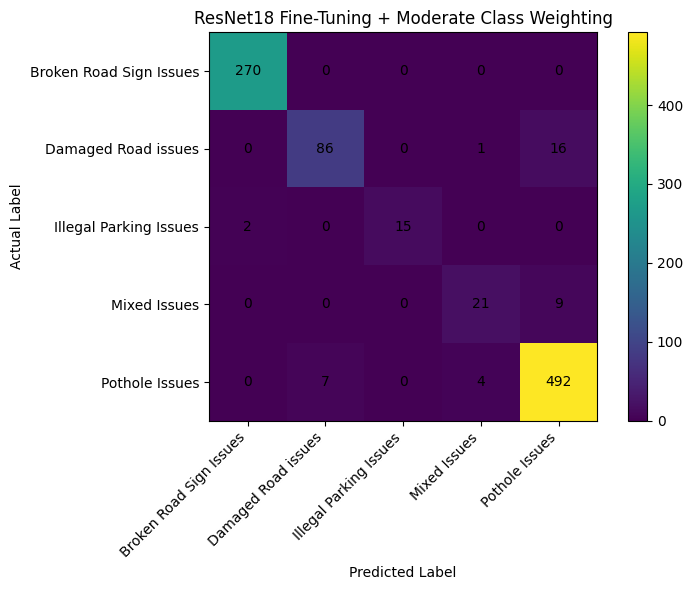

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title(
    "ResNet18 Fine-Tuning + Moderate Class Weighting"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    range(num_classes),
    train_dataset.classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(num_classes),
    train_dataset.classes
)

for i in range(num_classes):

    for j in range(num_classes):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()


In [ ]:
torch.save(
    model.state_dict(),
    "/content/resnet18_finetuned_road_model.pth"
)

print(
    "Model saved as "
    "resnet18_finetuned_road_model.pth"
)


Model saved as resnet18_finetuned_road_model.pth
